# Figure 6 — Discrimination performance under the 2025 holdout and early-2026 forecast-input evaluations

- **FIG_ID**: `Figure 6`（编号真源：`data/figure_numbering.csv`，§4.0；output stem `Figure_6`）
- **图位**: v6 正文行 256（§4.5）；对应 `[FIGURE 6 PLACEHOLDER]`
- **数据依赖**（A 层冻结，SHA-256 见 `data/figure_data_manifest.json`）:
  - `data/fig06_roc_points.csv`（(a) ROC 曲线点：2025 holdout = m1 链 / 2026 = 臂 H p_raw）
  - `data/fig06_pr_points.csv`（(b) PR 曲线点，同设计）
  - `data/fig06_summary.csv`（汇总指标 + Table 4/6 两步入舍显示值）
  - `data/fig06_assertions.csv`（取数断言回执 A1–A6，38 条全过才允许出图）
- **上游变更提示**: 若 temporal_cache 或 p3_arm_predictions 更新，先运行
  `python scripts/extract_fig06_data.py` 重新冻结，再执行本册（Cell 3 会拦截哈希不匹配）
- **输出**: `out/draft/Figure_6.{png,pdf,eps}`（`FIG_DRAFT=1`，默认）/ `out/submission/Figure_6.*`
  （`FIG_DRAFT=0`）+ `out/captions/Figure_6_caption.txt` + `qc/figure_6_qc.json`
- **图面约束**（导师意见 2026-10-08 重绘后）: 正文只保留 (a) ROC、(b) PR 两面板；
  原 (c) 校准面板删除（与 Figure 7(a) 重复）；图内不放横幅，
  "different evaluation designs" 声明移入图注；图例写全评价设计 + 三位小数 AUC/AP；
  (b) 基线率只作一个图例项 "Event prevalence"，图内不标灰色文字；
  m2 链（泄漏敏感性诊断，AUC≈0.800）**不入图**；图内禁用 m1/arm H 等内部代号
- **视觉编码（计划书 §1.6，v2.3.1）**: 颜色 = 时域（D+1 = NJU purple `#6E0F6D`，D+2 = accent
  `#D89000`）；线型 = 评价设计（实线 = 2025 measured-input holdout，虚线 = early-2026
  forecast-input evaluation）；参考线深灰 `#4A4A4A` 细于主曲线；字号取自 `fig_common.DS`
- **表述边界**: 图注只写 *potential utility for risk screening*；禁止 operational value /
  intervention effectiveness 的声称（以否定式免责声明出现）


In [1]:
%load_ext autoreload
%autoreload 2

import os
import sys
import time
from pathlib import Path

sys.path.append(str(Path.cwd().parent / "scripts"))
from fig_common import *          # 样式、色板、导出、核验（唯一来源，勿在本册硬编码样式）
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---- 本图配置 -------------------------------------------------------------
FIG_ID = "Figure 6"
IS_DRAFT = os.environ.get("FIG_DRAFT", "1") == "1"   # 1 -> out/draft；0 -> out/submission
DATA_FILES = ["fig06_roc_points.csv", "fig06_pr_points.csv",
              "fig06_summary.csv", "fig06_assertions.csv"]
t0 = time.time()
meta = figure_meta(FIG_ID)
print(f"FIG_ID={FIG_ID}  stem={meta['filename_stem']}  IS_DRAFT={IS_DRAFT}")
print("输出目录:", FIG_OUT_DRAFT if IS_DRAFT else FIG_OUT_SUB)


FIG_ID=Figure 6  stem=Figure_6  IS_DRAFT=True
输出目录: D:\NJU_folder\final_update\15_paper\figure\out\draft


In [2]:
# ---- 数据加载与核验（不匹配即中断）---------------------------------------
report = verify_figure_data(FIG_ID, data_files=DATA_FILES)
roc = pd.read_csv(FIG_DATA / "fig06_roc_points.csv")
pr = pd.read_csv(FIG_DATA / "fig06_pr_points.csv")
summ = pd.read_csv(FIG_DATA / "fig06_summary.csv")
chk = pd.read_csv(FIG_DATA / "fig06_assertions.csv")

# 结构性自检（防止冻结文件被替换成"形似而数不同"的内容）
assert set(roc.design) == {"holdout2025", "eval2026"} and set(roc.horizon) == {"D+1", "D+2"}
assert set(pr.design) == {"holdout2025", "eval2026"}
assert len(summ) == 4 and bool(summ[["match_roc", "match_pr", "match_base", "match_ratio"]].all().all())
assert bool(chk.passed.all()), "取数断言存在失败项，禁止出图"
assert int(summ.loc[summ.design == "holdout2025", "n"].iloc[0]) == 9124
assert int(summ.loc[summ.design == "eval2026", "n"].iloc[0]) == 1900
print("核验通过:", report["checked"])
print()
print(summ[["design", "horizon", "n", "crash_days", "base_rate", "display_roc_auc",
            "display_pr_auc", "pr_over_base", "mean_predicted"]].to_string(index=False))


核验通过: [{'file': 'fig06_roc_points.csv', 'sha256': '2c4a2d5067db16ce', 'rows': 5207}, {'file': 'fig06_pr_points.csv', 'sha256': '87d1b6cd160514b5', 'rows': 21122}, {'file': 'fig06_summary.csv', 'sha256': 'a5b5b88e99b97d30', 'rows': 4}, {'file': 'fig06_assertions.csv', 'sha256': 'f0ef3d1a33fcf474', 'rows': 38}]

     design horizon    n  crash_days  base_rate  display_roc_auc  display_pr_auc  pr_over_base  mean_predicted
holdout2025     D+1 9124        1089   0.119356            0.746           0.327        2.7375        0.160239
holdout2025     D+2 9124        1089   0.119356            0.746           0.336        2.8124        0.167891
   eval2026     D+1 1900         212   0.111579            0.718           0.281        2.5137        0.130862
   eval2026     D+2 1900         212   0.111579            0.714           0.264        2.3612        0.126236


        xlim=(0.0, 1.0)  ylim=(0.0, 1.0)
        xlim=(0.0, 1.0)  ylim=(0.0, 1.0)


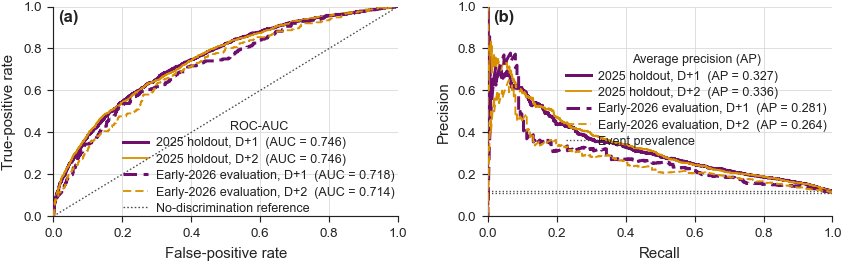

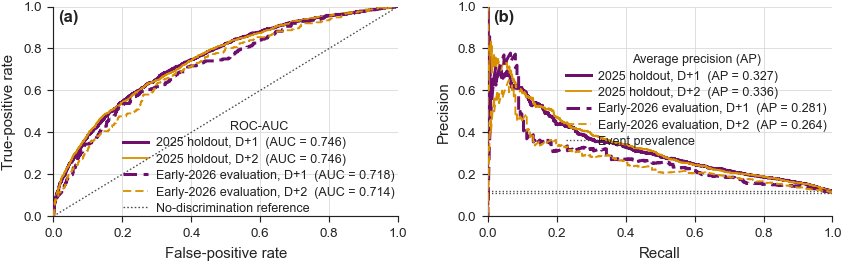

In [3]:
# ---- 绘图逻辑：ROC + PR 两 panel ------------------------------------------
# 面板装配代码放在同图模块 fig06_temporal_core.build_figure() 内，
# 使命令行试绘（--draft/--submission）与本册出图共用唯一实现，避免两处拷贝漂移。
from fig06_temporal_core import build_figure

fig = build_figure()
for ax in fig.get_axes():
    print(f"{ax.get_label():>6s}  xlim={tuple(round(float(v), 4) for v in ax.get_xlim())}  "
          f"ylim={tuple(round(float(v), 4) for v in ax.get_ylim())}")
fig


In [4]:
# ---- 导出双版本 + caption + qc -------------------------------------------
written = export_figure(fig, FIG_ID, is_draft=IS_DRAFT)
print("\n".join(str(p) for p in written))

from fig06_temporal_core import CAPTION, TITLE

cap = write_caption(FIG_ID, CAPTION, title=TITLE)
print(cap)

qc = fig_qc_dump(FIG_ID, {
    "status": "ok", "is_draft": IS_DRAFT, "seconds": round(time.time() - t0, 1),
    "data_checked": report["checked"], "data_files": DATA_FILES,
    "outputs": [{"path": str(p), "bytes": p.stat().st_size, "sha256": sha256_file(p)} for p in written],
    "caption": str(cap),
})
print(qc)


D:\NJU_folder\final_update\15_paper\figure\out\draft\Figure_6.png
D:\NJU_folder\final_update\15_paper\figure\out\draft\Figure_6.pdf
D:\NJU_folder\final_update\15_paper\figure\out\draft\Figure_6.eps
D:\NJU_folder\final_update\15_paper\figure\out\captions\Figure_6_caption.txt
D:\NJU_folder\final_update\15_paper\figure\qc\figure_6_qc.json
